# Analysis 6: How do India, the US and the UK differ, and what crosses borders?

**Business question.** Can a media company treat these three markets as one audience, or does each need its own content plan? Two parts: do the countries trend different kinds of content (category mix), and how much of the same content trends in more than one country (overlap)?

**Method.** Chi-square test of independence on the country-by-category table of trending videos, with Cramer's V as the effect size and Pearson residuals to show which categories drive the difference. Overlap is measured with shared video counts and the Jaccard index (shared videos divided by all videos trending in either country), quarter by quarter to check it is stable. All trending videos from 2020-08-12 to 2024-04-15 are included.

In [1]:
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

from streampulse.charts import (
    COUNTRIES, COUNTRY_NAMES, DIVERGING_RAMP, SINGLE_SERIES_COLOR, apply_chart_style,
)
from streampulse.database import connect

COUNTRY_PAIRS = [("US", "GB"), ("IN", "US"), ("IN", "GB")]

apply_chart_style()
with connect() as connection:
    videos = connection.execute("""
        SELECT country, video_id, channel_id, channel_title, category, first_trending_date
        FROM trending_videos
    """).df()

videos.groupby("country").agg(videos=("video_id", "nunique"), channels=("channel_id", "nunique")).loc[COUNTRIES]

,videos,channels
country,,
IN,78847,4521
US,47142,8298
GB,47607,7568


## 1. Category mix

In [2]:
def cramers_v(contingency_table):
    chi2, _, _, _ = stats.chi2_contingency(contingency_table)
    return np.sqrt(chi2 / (contingency_table.to_numpy().sum() * (min(contingency_table.shape) - 1)))


category_counts = pd.crosstab(videos["category"], videos["country"])[COUNTRIES]
chi2, p_value, degrees_of_freedom, expected_counts = stats.chi2_contingency(category_counts)
print(f"All three countries: chi-squared = {chi2:,.0f}, df = {degrees_of_freedom}, p = {p_value:.1g}, "
      f"Cramer's V = {cramers_v(category_counts):.3f}, smallest expected count = {expected_counts.min():.1f}")
for first_country, second_country in COUNTRY_PAIRS:
    pair_counts = category_counts[[first_country, second_country]]
    pair_counts = pair_counts[pair_counts.sum(axis=1) > 0]
    print(f"{first_country} vs {second_country}: Cramer's V = {cramers_v(pair_counts):.3f}")

All three countries: chi-squared = 26,029, df = 28, p = 0, Cramer's V = 0.274, smallest expected count = 18.2
US vs GB: Cramer's V = 0.124
IN vs US: Cramer's V = 0.372
IN vs GB: Cramer's V = 0.392


Cramer's V runs from 0 (identical mix) to 1 (no overlap at all). Around 0.1 is small and 0.3 to 0.4 is moderate to large for a table this size. The Pearson residuals below show where each country has more (blue) or fewer (red) videos in a category than it would if all three countries had the same mix.

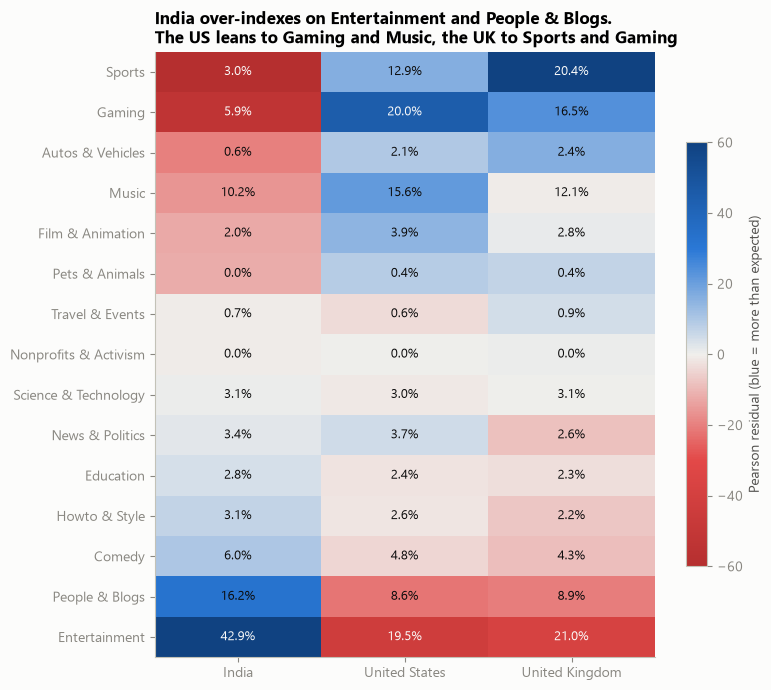

country,IN,US,GB
category,,,
Entertainment,62.7,-43.4,-37.5
People & Blogs,32.8,-22.0,-20.3
Comedy,9.9,-4.2,-8.5
Howto & Style,6.6,-1.4,-7.1
Education,4.0,-2.3,-2.8
News & Politics,2.3,5.2,-8.1
Science & Technology,0.6,-1.0,0.2
Nonprofits & Activism,-0.8,0.2,0.8
Travel & Events,-0.8,-3.4,4.5


In [3]:
pearson_residuals = (category_counts - expected_counts) / np.sqrt(expected_counts)
category_share = (100 * category_counts / category_counts.sum()).round(1)
residual_order = pearson_residuals["IN"].sort_values().index

fig, ax = plt.subplots(figsize=(8, 7))
residual_limit = 60
heatmap = ax.imshow(pearson_residuals.loc[residual_order], cmap=DIVERGING_RAMP, vmin=-residual_limit,
                    vmax=residual_limit, aspect="auto")
for row, category in enumerate(residual_order):
    for column, country in enumerate(COUNTRIES):
        dark_cell = abs(pearson_residuals.loc[category, country]) > 0.6 * residual_limit
        ax.text(column, row, f"{category_share.loc[category, country]:.1f}%", ha="center", va="center", fontsize=9,
                color="#fcfcfb" if dark_cell else "#0b0b0b")
ax.set_xticks(range(3), [COUNTRY_NAMES[country] for country in COUNTRIES])
ax.set_yticks(range(len(residual_order)), residual_order)
ax.grid(False)
fig.colorbar(heatmap, ax=ax, shrink=0.7, label="Pearson residual (blue = more than expected)")
ax.set_title("India over-indexes on Entertainment and People & Blogs.\n"
             "The US leans to Gaming and Music, the UK to Sports and Gaming")
plt.tight_layout()
plt.show()

pearson_residuals.loc[residual_order[::-1]].round(1)

## 2. How much content is shared

For each pair of countries: how many videos trended in both, what share of each country's trending videos that is, the Jaccard index for videos, and the Jaccard index for channels.

In [4]:
videos_by_country = {country: set(rows["video_id"]) for country, rows in videos.groupby("country")}
channels_by_country = {country: set(rows["channel_id"]) for country, rows in videos.groupby("country")}


def jaccard(first_set, second_set):
    return len(first_set & second_set) / len(first_set | second_set)


overlap_rows = []
for first_country, second_country in COUNTRY_PAIRS:
    shared_videos = videos_by_country[first_country] & videos_by_country[second_country]
    overlap_rows.append({
        "pair": f"{first_country} + {second_country}",
        "shared_videos": len(shared_videos),
        f"pct_of_first": 100 * len(shared_videos) / len(videos_by_country[first_country]),
        f"pct_of_second": 100 * len(shared_videos) / len(videos_by_country[second_country]),
        "video_jaccard": jaccard(videos_by_country[first_country], videos_by_country[second_country]),
        "channel_jaccard": jaccard(channels_by_country[first_country], channels_by_country[second_country]),
    })
pd.DataFrame(overlap_rows).set_index("pair").round(3)

,shared_videos,pct_of_first,pct_of_second,video_jaccard,channel_jaccard
pair,,,,,
US + GB,24447,51.858,51.352,0.348,0.465
IN + US,1718,2.179,3.644,0.014,0.025
IN + GB,1994,2.529,4.188,0.016,0.033


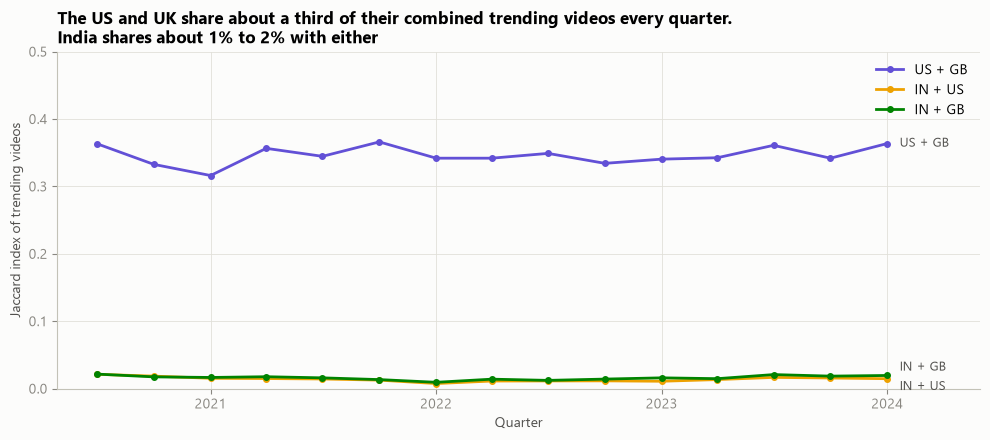

,US + GB,IN + US,IN + GB
min,0.316,0.008,0.009
mean,0.346,0.014,0.016
max,0.366,0.021,0.022


In [5]:
quarterly = videos.assign(quarter=videos["first_trending_date"].dt.to_period("Q"))
# The last quarter holds only 15 days of data, so it is left out.
quarterly = quarterly[quarterly["quarter"] < pd.Period("2024Q2")]
jaccard_by_quarter = pd.DataFrame({
    f"{first} + {second}": quarterly.groupby("quarter").apply(
        lambda rows, first=first, second=second: jaccard(
            set(rows.loc[rows["country"] == first, "video_id"]), set(rows.loc[rows["country"] == second, "video_id"])
        ),
        include_groups=False,
    )
    for first, second in COUNTRY_PAIRS
})

# Pairs get their own colors so they are not mistaken for single countries.
pair_colors = {"US + GB": "#6250d6", "IN + US": "#eda100", "IN + GB": "#008300"}
quarter_starts = mdates.date2num(jaccard_by_quarter.index.to_timestamp().to_pydatetime())
fig, ax = plt.subplots(figsize=(10, 4.5))
for label_offset, (pair, color) in zip([0, -0.012, 0.012], pair_colors.items()):
    ax.plot(quarter_starts, jaccard_by_quarter[pair], marker="o", markersize=4, color=color, label=pair)
    ax.text(quarter_starts[-1] + 20, jaccard_by_quarter[pair].iloc[-1] + label_offset, pair,
            va="center", fontsize=9, color="#52514e")
ax.xaxis.set_major_locator(mdates.YearLocator())
ax.xaxis.set_major_formatter(mdates.DateFormatter("%Y"))
ax.set_ylim(0, 0.5)
ax.set_xlim(None, quarter_starts[-1] + 150)
ax.set_ylabel("Jaccard index of trending videos")
ax.set_xlabel("Quarter")
ax.set_title("The US and UK share about a third of their combined trending videos every quarter.\n"
             "India shares about 1% to 2% with either")
ax.legend()
plt.tight_layout()
plt.show()

jaccard_by_quarter.describe().loc[["min", "mean", "max"]].round(3)

## 3. Which content crosses borders

Share of each category's videos that trended in more than one country, counting each video once.

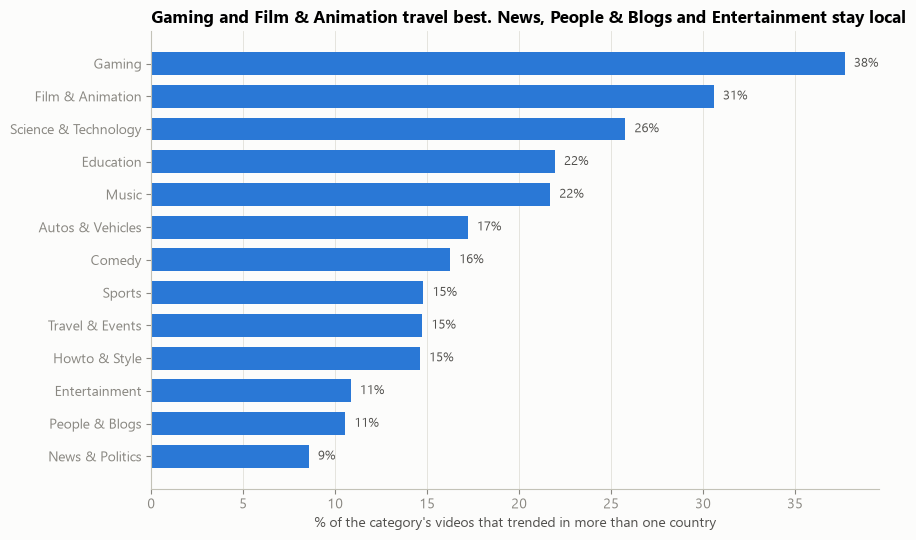

,videos,pct_multi_country
category,,
Gaming,15791,37.7
Film & Animation,3601,30.6
Science & Technology,4157,25.8
Education,3597,21.9
Music,16990,21.7
Autos & Vehicles,2233,17.2
Comedy,7780,16.2
Sports,15647,14.8
Travel & Events,1141,14.7


In [6]:
countries_per_video = videos.groupby("video_id").agg(
    countries=("country", "nunique"), category=("category", "first")
)
crossing_share = (
    countries_per_video.groupby("category")
    .agg(videos=("countries", "size"), pct_multi_country=("countries", lambda counts: 100 * (counts > 1).mean()))
    .query("videos >= 500")
    .sort_values("pct_multi_country")
)

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.barh(crossing_share.index, crossing_share["pct_multi_country"], color=SINGLE_SERIES_COLOR, height=0.7)
for y_position, share in enumerate(crossing_share["pct_multi_country"]):
    ax.text(share + 0.5, y_position, f"{share:.0f}%", va="center", fontsize=9, color="#52514e")
ax.set_xlabel("% of the category's videos that trended in more than one country")
ax.grid(axis="y", visible=False)
ax.set_title("Gaming and Film & Animation travel best. News, People & Blogs and Entertainment stay local")
plt.tight_layout()
plt.show()

crossing_share.iloc[::-1].round(1)

Channels whose videos most often trend in India and also in the US or UK:

In [7]:
india_crossovers = videos[
    (videos["country"] == "IN")
    & videos["video_id"].isin(videos_by_country["IN"] & (videos_by_country["US"] | videos_by_country["GB"]))
]
print(f"{len(india_crossovers):,} videos trended in India and in the US or UK")
india_crossovers.groupby(["channel_title", "category"]).size().rename("videos").sort_values(ascending=False).head(12).reset_index()

2,149 videos trended in India and in the US or UK


,channel_title,category,videos
0,Clash of Clans,Gaming,75
1,BANGTANTV,Music,71
2,MrBeast,Entertainment,69
3,HYBE LABELS,Music,64
4,Dude Perfect,Sports,61
5,Marvel Entertainment,Entertainment,59
6,BLACKPINK,Music,50
7,England & Wales Cricket Board,Sports,41
8,Apple,Science & Technology,40
9,Marques Brownlee,Science & Technology,40


## 4. Does one country lead the others?

For videos that trended in two countries, the difference in days between their first trending days.

In [8]:
first_day_by_country = videos.pivot_table(index="video_id", columns="country", values="first_trending_date", aggfunc="min")
lead_rows = []
for first_country, second_country in COUNTRY_PAIRS:
    shared = first_day_by_country.dropna(subset=[first_country, second_country])
    lag_days = (shared[second_country] - shared[first_country]).dt.days
    lead_rows.append({
        "pair": f"{first_country} + {second_country}",
        "shared_videos": len(shared),
        "pct_same_day": 100 * (lag_days == 0).mean(),
        f"pct_first_country_earlier": 100 * (lag_days > 0).mean(),
        f"pct_second_country_earlier": 100 * (lag_days < 0).mean(),
    })
pd.DataFrame(lead_rows).set_index("pair").round(1)

,shared_videos,pct_same_day,pct_first_country_earlier,pct_second_country_earlier
pair,,,,
US + GB,24447,74.0,13.7,12.4
IN + US,1718,66.9,25.1,8.0
IN + GB,1994,67.4,24.5,8.1


## Finding

**The US and UK behave like one market for trending content. India is a separate market.**

- **Category mix differs significantly** (chi-squared 26,029, df 28, p < 0.001, Cramer's V 0.27). India differs strongly from both the US (V 0.37) and the UK (V 0.39); the US and UK differ only a little (V 0.12).
- **What drives the difference:** India has far more Entertainment (42.9% of its trending videos against about 20%) and People & Blogs (16.2% against about 9%). The US leans to Gaming (20.0%) and Music (15.6%), the UK to Sports (20.4%) and Gaming (16.5%). India has very little Sports (3.0%) or Gaming (5.9%).
- **The US and UK share about half their trending videos**: 24,447 videos, 52% of each country's list, Jaccard 0.35 for videos and 0.47 for channels. India shares 2.2% of its videos with the US and 2.5% with the UK (Jaccard 0.014 to 0.016). These levels are stable: US-UK Jaccard stayed between 0.32 and 0.37 in every full quarter.
- **What travels:** Gaming (38% of its videos trend in more than one country), Film & Animation (31%) and Science & Technology (26%). News & Politics (9%), People & Blogs (10%) and Entertainment (11%) stay local. Into India, the content that crosses is global brands and K-pop: Clash of Clans, BTS (BANGTANTV, HYBE LABELS), MrBeast, Dude Perfect, Marvel, BLACKPINK, Apple, Marques Brownlee, and English cricket.
- **No country leads the US and UK.** Shared videos start trending on the same day 74% of the time; the US is earlier in 13.7% of cases and the UK in 12.4%. For videos shared with India, India's list is earlier in about 25% of cases against 8% the other way, consistent with its faster intake (analysis 1).

**Business answer.** A content plan for the US can largely serve the UK too. India needs its own plan, built on local entertainment and creators; the content that does cross into India is global gaming, K-pop, big-brand launches and a few global creators.

**Limitations**

- Categories are chosen by uploaders and are broad.
- India's list has more videos per day and turns over faster, so overlap shares are not symmetric (2.2% of India's videos but 3.6% of the US's).
- "Which country is earlier" uses daily list dates and inherits the capture-timing issue from analysis 1, so it is only a rough guide.